# Tiranex Task 4: Data Cleaning & Reporting Automation

## Objective

The objective of this project is to automate the data cleaning and reporting process using Python.

The workflow includes:
- Loading the raw sales dataset
- Checking missing values and duplicate records
- Identifying inconsistent data
- Cleaning and preprocessing the dataset
- Generating data quality reports
- Creating visual summaries
- Exporting the cleaned dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_excel("Tiranex_Task_1_Sales_Dataset.xlsx")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 600
Columns: 12


In [3]:
df.head()

,Order Date,Order ID,Customer,Product,Category,Region,Quantity,Unit Price,Discount,Sales Amount,Cost Amount,Profit
0,2025-01-01,ORD-10538,Customer 044,Wireless Charger,Accessories,East,6,2526,0.02,14852.88,11701.63,3151.25
1,2025-01-01,ORD-10320,Customer 072,Tablet,Electronics,East,4,22799,0.00,91196.00,68493.35,22702.65
2,2025-01-02,ORD-10226,Customer 049,Office Chair,Office,Central,4,8567,0.02,33582.64,24920.56,8662.08
3,2025-01-03,ORD-10221,Customer 026,Power Bank,Accessories,South,3,1702,0.00,5106.00,3781.96,1324.04
4,2025-01-04,ORD-10571,Customer 023,Smartwatch,Electronics,South,6,7056,0.10,38102.40,26910.21,11192.19


In [4]:
print("===== DATA QUALITY REPORT =====")

print("\n1. Dataset Shape:")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\n2. Missing Values:")
print(df.isnull().sum())

print("\n3. Duplicate Rows:")
print(df.duplicated().sum())

print("\n4. Data Types:")
print(df.dtypes)

===== DATA QUALITY REPORT =====

1. Dataset Shape:
Rows: 600
Columns: 12

2. Missing Values:
Order Date      0
Order ID        0
Customer        0
Product         0
Category        0
Region          0
Quantity        0
Unit Price      0
Discount        0
Sales Amount    0
Cost Amount     0
Profit          0
dtype: int64

3. Duplicate Rows:
0

4. Data Types:
Order Date      datetime64[ns]
Order ID                object
Customer                object
Product                 object
Category                object
Region                  object
Quantity                 int64
Unit Price               int64
Discount               float64
Sales Amount           float64
Cost Amount            float64
Profit                 float64
dtype: object


In [5]:
# Create a copy so the original dataset remains unchanged
cleaned_df = df.copy()

# 1. Remove duplicate rows
duplicates_before = cleaned_df.duplicated().sum()
cleaned_df = cleaned_df.drop_duplicates()
duplicates_removed = duplicates_before - cleaned_df.duplicated().sum()

# 2. Standardize text columns
text_columns = ["Order ID", "Customer", "Product", "Category", "Region"]

for column in text_columns:
    cleaned_df[column] = cleaned_df[column].astype(str).str.strip()

# 3. Make sure the date column is in proper datetime format
cleaned_df["Order Date"] = pd.to_datetime(
    cleaned_df["Order Date"],
    errors="coerce"
)

# 4. Check for missing values after cleaning
missing_after = cleaned_df.isnull().sum().sum()

# 5. Create a cleaning summary
print("===== CLEANING SUMMARY =====")
print("Original rows:", len(df))
print("Rows after cleaning:", len(cleaned_df))
print("Duplicate rows removed:", duplicates_removed)
print("Missing values after cleaning:", missing_after)

===== CLEANING SUMMARY =====
Original rows: 600
Rows after cleaning: 600
Duplicate rows removed: 0
Missing values after cleaning: 0


In [6]:
# Generate statistical summary report

statistical_report = cleaned_df.describe()

print("===== STATISTICAL SUMMARY REPORT =====")

statistical_report

===== STATISTICAL SUMMARY REPORT =====


,Order Date,Quantity,Unit Price,Discount,Sales Amount,Cost Amount,Profit
count,600,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,2025-11-06 12:57:36,4.086667,10373.013333,0.045850,39412.478433,28080.042617,11332.435817
min,2025-01-01 00:00:00,1.000000,455.000000,0.000000,452.200000,354.630000,95.590000
25%,2025-06-08 18:00:00,2.000000,2412.000000,0.000000,8417.925000,5857.425000,2214.975000
50%,2025-11-02 00:00:00,4.000000,6008.500000,0.050000,20275.630000,14134.680000,5401.650000
75%,2026-04-07 00:00:00,6.000000,11413.500000,0.100000,43647.500000,32248.277500,12746.307500
max,2026-08-31 00:00:00,7.000000,71396.000000,0.150000,437843.000000,325037.280000,152480.870000
std,NaN,1.955897,13696.347862,0.042996,57003.679141,40400.173374,17277.618017


In [7]:
category_report = (
    cleaned_df.groupby("Category")
    .agg(
        Total_Sales=("Sales Amount", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Number_of_Orders=("Order ID", "nunique")
    )
    .reset_index()
)

category_report

,Category,Total_Sales,Total_Profit,Total_Quantity,Number_of_Orders
0,Accessories,1261409.61,342195.60,651,150
1,Electronics,12885457.52,3722526.59,564,144
2,Home & Kitchen,4488524.87,1281106.22,615,155
3,Office,5012095.06,1453633.08,622,151


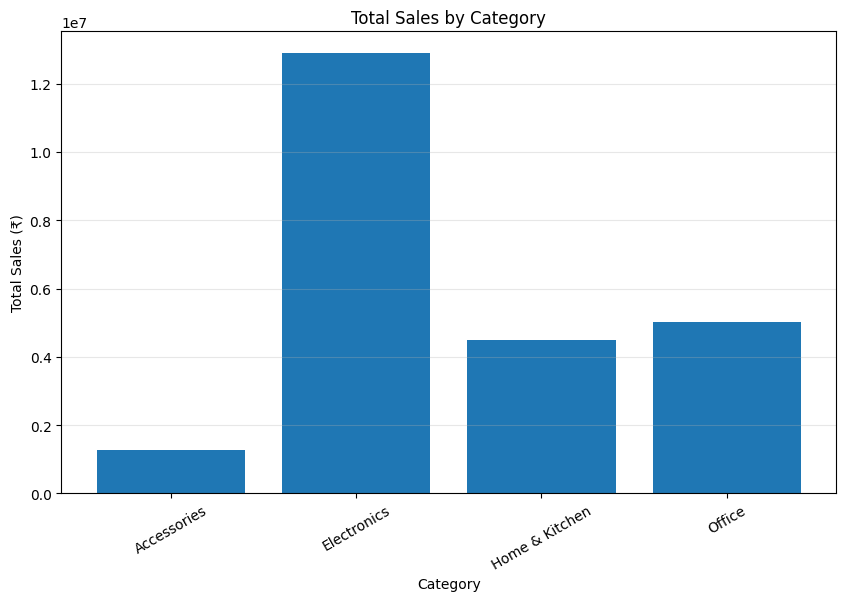

In [8]:
plt.figure(figsize=(10, 6))

plt.bar(
    category_report["Category"],
    category_report["Total_Sales"]
)

plt.xlabel("Category")
plt.ylabel("Total Sales (₹)")
plt.title("Total Sales by Category")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.show()

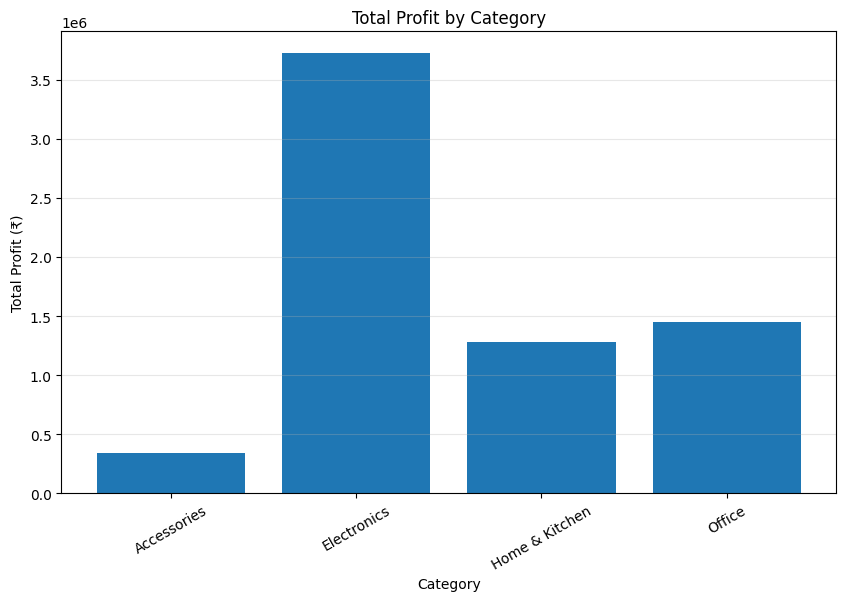

In [9]:
plt.figure(figsize=(10, 6))

plt.bar(
    category_report["Category"],
    category_report["Total_Profit"]
)

plt.xlabel("Category")
plt.ylabel("Total Profit (₹)")
plt.title("Total Profit by Category")

plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)

plt.show()

In [10]:
# Export cleaned dataset
cleaned_df.to_csv(
    "Tiranex_Task_4_Cleaned_Sales_Data.csv",
    index=False
)

# Export category-wise business report
category_report.to_csv(
    "Tiranex_Task_4_Category_Report.csv",
    index=False
)

# Export statistical summary
statistical_report.to_csv(
    "Tiranex_Task_4_Statistical_Report.csv"
)

print("All reports generated successfully!")

All reports generated successfully!


In [11]:
# Automated Data Quality Report

data_quality_report = pd.DataFrame({
    "Metric": [
        "Original Rows",
        "Rows After Cleaning",
        "Original Columns",
        "Missing Values",
        "Duplicate Rows Removed"
    ],
    "Value": [
        len(df),
        len(cleaned_df),
        df.shape[1],
        cleaned_df.isnull().sum().sum(),
        duplicates_removed
    ]
})

print("===== AUTOMATED DATA QUALITY REPORT =====")
data_quality_report

===== AUTOMATED DATA QUALITY REPORT =====


,Metric,Value
0,Original Rows,600
1,Rows After Cleaning,600
2,Original Columns,12
3,Missing Values,0
4,Duplicate Rows Removed,0


In [12]:
data_quality_report.to_csv(
    "Tiranex_Task_4_Data_Quality_Report.csv",
    index=False
)

print("Data quality report saved successfully!")

Data quality report saved successfully!


## Final Summary

This project automated the data cleaning and reporting workflow for a sales dataset containing 600 records and 12 columns.

The workflow performed:
- Dataset loading and inspection
- Missing-value detection
- Duplicate detection and removal
- Text standardization
- Date-format standardization
- Statistical analysis
- Category-wise sales and profit analysis
- Automated visual reporting
- Export of cleaned data and business reports

### Data Quality Results

- Original records: 600
- Records after cleaning: 600
- Missing values: 0
- Duplicate records removed: 0
- Columns: 12

### Business Insights

- Electronics generated the highest total sales and total profit among the four categories.
- Home & Kitchen and Office also contributed substantial sales and profit.
- Accessories recorded the lowest total sales and profit among the categories.
- The automated reports can be regenerated whenever the source dataset is updated.

## Conclusion

The project demonstrates how Python and Pandas can be used to automate data cleaning, quality checking, business reporting, and visualization. The automated workflow reduces repetitive manual work and produces reusable cleaned datasets and summary reports.

In [13]:
from google.colab import files

files.download("Tiranex_Task_4_Cleaned_Sales_Data.csv")
files.download("Tiranex_Task_4_Category_Report.csv")
files.download("Tiranex_Task_4_Statistical_Report.csv")
files.download("Tiranex_Task_4_Data_Quality_Report.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>